# Chapitre 10 - Exercices 10.6 à 10.10

Ce notebook traite les exercices sur les jointures, l'asymétrie, Pregel et les sorties
des jobs :

- **10.6** : une jointure tri-fusion qui donne des résultats faux : trouver le bogue
  (raisonnement et code) ;
- **10.7** : choisir l'algorithme de jointure selon la taille et le partitionnement
  des entrées (calcul) ;
- **10.8** : une célébrité dans la jointure : clé chaude et salage (calcul et
  simulation) ;
- **10.9** : plus courts chemins en Pregel (mini-lab) ;
- **10.10** : écrire dans la base de production ou construire et basculer ? (calcul et
  raisonnement).



In [1]:
import heapq
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import batch as B
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## Exercice 10.6 : une jointure tri-fusion qui donne des résultats faux

**Énoncé.** Un collègue écrit la jointure du cours 3 (événements enrichis de l'année de
naissance de l'utilisateur) avec un tri secondaire. Sa version tourne sans erreur...
mais ne produit aucun événement enrichi.

```python
def mappeur(rec):
    if "birth" in rec:
        yield (rec["user_id"], 0, 0), rec["birth"]
    else:
        yield (rec["user_id"], 1, rec["ts"]), rec["url"]

def reducteur(cle, valeurs):        # cle = (user_id, étiquette, date)
    naissance = next(valeurs)
    for url in valeurs:
        yield [url, naissance]

B.run_mapreduce(entrees, mappeur, reducteur, n_reducers=4)      # pas de group_by
```

1. Exécuter ce job sur un petit jeu de données et constater le problème.
2. Expliquer précisément ce qui se passe (partitionnement, regroupement).
3. Corriger. Que faire des événements dont l'utilisateur n'existe pas dans l'export
   (jointure interne ou externe) ?

**Rappels.** Jointure tri-fusion côté reduce, tri secondaire : on trie sur la clé
complète, mais on **partitionne et regroupe** sur l'identifiant (cours 3, section 4,
section *Reduce-Side Joins and Grouping*).

In [2]:
users = B.make_users(200, seed=1)
events = B.make_events(2000, 210, n_urls=20, seed=2)          # quelques événements d'utilisateurs absents (200 à 209)
entrees = [users[:100], users[100:], events[:1000], events[1000:]]


def mappeur(rec):
    if "birth" in rec:
        yield (rec["user_id"], 0, 0), rec["birth"]
    else:
        yield (rec["user_id"], 1, rec["ts"]), rec["url"]


def reducteur_bogue(cle, valeurs):
    naissance = next(valeurs)
    for url in valeurs:
        yield [url, naissance]


rows = []
for R in [1, 4]:
    out, st = B.run_mapreduce(entrees, mappeur, reducteur_bogue, n_reducers=R)
    sortie = [x for o in out for x in o]
    rows.append({"version": f"boguée, {R} réducteur(s)", "groupes vus par les réducteurs": st.reduce_groups,
                 "événements en sortie": len(sortie),
                 "« naissances » qui sont des URL": sum(isinstance(x[1], str) for x in sortie)})
pd.DataFrame(rows).set_index("version")

,groupes vus par les réducteurs,événements en sortie,« naissances » qui sont des URL
version,,,
"boguée, 1 réducteur(s)",2200,0,0
"boguée, 4 réducteur(s)",2200,0,0


**Solution.**

*2.* Sans `group_by`, la clé de **regroupement** est la clé complète (identifiant,
étiquette, date) : chaque événement forme son propre groupe, d'un seul élément. Le
réducteur appelle `next(valeurs)` qui consomme cet unique élément comme « naissance »,
puis la boucle ne trouve rien : tous les événements disparaissent (seuls d'éventuels
événements d'un même utilisateur au même horodatage formeraient un groupe de deux, et
leur « naissance » serait une URL). Dans `B.run_mapreduce`, le partitionnement suit la
clé de regroupement ; dans Hadoop, partitionneur et comparateur de regroupement se
configurent séparément, et oublier le partitionneur envoie l'utilisateur et ses
événements chez des réducteurs différents : le résultat dépend alors du nombre de
réducteurs, ce qui est encore plus difficile à diagnostiquer.

*3.* Il faut partitionner et regrouper sur `cle[0]` (paramètre `group_by`), et vérifier
que la première valeur est bien une naissance : si l'utilisateur est absent de l'export,
le premier élément est déjà un événement. Jointure **interne** : on ignore ces
événements ; jointure **externe gauche** : on les garde avec une naissance inconnue.
Le choix est métier, mais il doit être explicite (et compté).

In [3]:
def reducteur_externe(uid, valeurs):
    premier = next(valeurs)
    if isinstance(premier, int):           # c'est bien la naissance
        naissance = premier
    else:                                  # utilisateur absent de l'export : jointure externe gauche
        naissance = None
        yield [premier, None]
    for url in valeurs:
        yield [url, naissance]


out, st = B.run_mapreduce(entrees, mappeur, reducteur_externe, n_reducers=4, group_by=lambda k: k[0])
sortie = [x for o in out for x in o]
orphelins = sum(x[1] is None for x in sortie)
attendus = sum(e["user_id"] >= 200 for e in events)
ref = B.sort_merge_join(events, users, "user_id")
pd.DataFrame({"valeur": [len(sortie), len(events), orphelins, attendus, len(ref)]},
             index=["événements en sortie (corrigé)", "événements en entrée", "dont sans utilisateur (naissance inconnue)",
                    "événements d'utilisateurs absents (attendu)", "jointure interne de référence"])

,valeur
événements en sortie (corrigé),2000
événements en entrée,2000
dont sans utilisateur (naissance inconnue),103
événements d'utilisateurs absents (attendu),103
jointure interne de référence,1897


La version corrigée restitue les 2 000 événements, dont ceux des utilisateurs absents
marqués « inconnu » ; la jointure interne de référence en garde le complément exact.

> **À retenir.** Dans un tri secondaire, la clé de tri, la clé de partitionnement et la
> clé de regroupement sont **trois choses distinctes** : on trie sur la clé composite, on
> partitionne et on regroupe sur la clé de jointure. Et l'on décide explicitement du
> sort des enregistrements sans correspondance.

## Exercice 10.7 : choisir l'algorithme de jointure

**Énoncé.** Un cluster de $W = 200$ machines, avec 16 Go de mémoire utilisable par
tâche, doit joindre une table d'événements de 2 To avec, selon le cas :

- (a) une table des pays de 50 Mo ;
- (b) une table d'utilisateurs de 300 Go, sans partitionnement particulier ;
- (c) la même table d'utilisateurs, mais les deux tables sortent de jobs précédents
  qui les ont partitionnées par `user_id` en 1 000 partitions avec la même fonction
  de hachage ;
- (d) une table de produits de 12 Go.

Pour chaque cas, calculer le volume réseau d'une jointure tri-fusion côté reduce (shuffle)
et d'une jointure par hachage diffusé, vérifier la contrainte de mémoire, et choisir.

**Rappels.** Volumes réseau : shuffle $(G + p)(1 - 1/W)$, diffusion $p\,(W-1)$ ;
hachage partitionné si co-partitionnement ; cours 3, section 6 (section *Map-Side Joins*).

**Solution.**

- (a) Diffusion : $50 \text{ Mo} \times 199 \approx 10$ Go, contre $\approx 2$ To pour le
  shuffle ; 50 Mo tiennent en mémoire. **Hachage diffusé**, sans hésitation.
- (b) Diffusion : $300 \times 199 = 59{,}7$ To, et 300 Go ne tiennent pas dans 16 Go.
  **Tri-fusion côté reduce** (≈ 2,3 To de shuffle).
- (c) Co-partitionnées : le mappeur $i$ charge la partition $i$ des utilisateurs, soit
  300 Go / 1 000 = 300 Mo, qui tiennent en mémoire ; rien ne circule. **Hachage
  partitionné**.
- (d) Diffusion : $12 \times 199 \approx 2{,}4$ To, du même ordre que le shuffle
  (≈ 2,0 To), et 12 Go tiennent tout juste dans 16 Go. Le seuil vaut $G/(W-1) \approx
  10$ Go : on est juste au-dessus, le **shuffle** est légèrement préférable ; avec 100
  machines, la diffusion l'emporterait. Les deux sont défendables : un optimiseur
  trancherait d'après des statistiques fiables, et le risque de dépasser la mémoire
  pousse vers le shuffle.

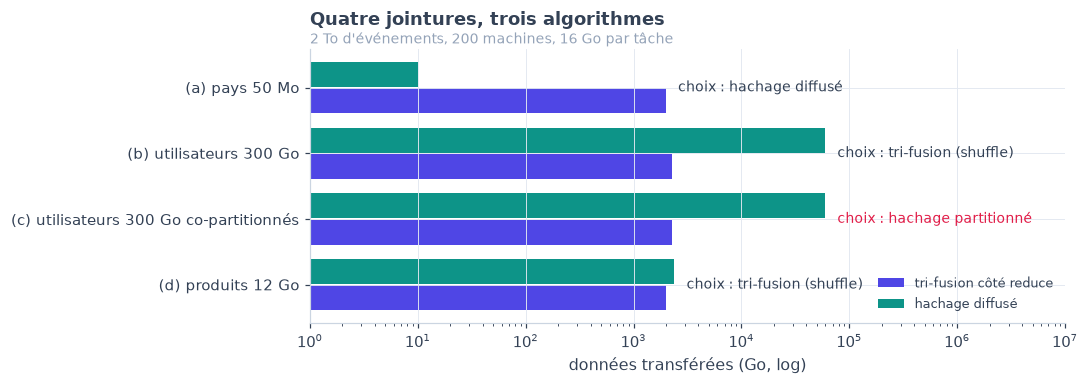

,shuffle (Go),diffusion (Go),tient en mémoire,co-partitionné (Go),choix
cas,,,,,
(a) pays 50 Mo,1990.0,10.0,True,NaN,hachage diffusé
(b) utilisateurs 300 Go,2288.5,59700.0,False,NaN,tri-fusion (shuffle)
(c) utilisateurs 300 Go co-partitionnés,2288.5,59700.0,True,0.0,hachage partitionné
(d) produits 12 Go,2001.9,2388.0,True,NaN,tri-fusion (shuffle)


In [4]:
W, G = 200, 2000.0
cas = {"(a) pays 50 Mo": (0.05, False), "(b) utilisateurs 300 Go": (300, False),
       "(c) utilisateurs 300 Go co-partitionnés": (300, True), "(d) produits 12 Go": (12, False)}
rows = []
for nom, (p, copart) in cas.items():
    sh = B.join_network_cost(G, p, W, "shuffle")
    bc = B.join_network_cost(G, p, W, "broadcast")
    tient = p <= 16
    if copart:
        choix = "hachage partitionné"
    elif tient and bc < sh:
        choix = "hachage diffusé"
    else:
        choix = "tri-fusion (shuffle)"
    rows.append({"cas": nom, "shuffle (Go)": sh, "diffusion (Go)": bc, "tient en mémoire": tient or copart,
                 "co-partitionné (Go)": 0.0 if copart else np.nan, "choix": choix})
T = pd.DataFrame(rows).set_index("cas")
fig, ax = plt.subplots(figsize=(10, 3.6))
y = np.arange(len(T))
ax.barh(y + 0.2, T["shuffle (Go)"], height=0.38, color=INDIGO, label="tri-fusion côté reduce")
ax.barh(y - 0.2, T["diffusion (Go)"], height=0.38, color=TEAL, label="hachage diffusé")
for i, (nom, r) in enumerate(T.iterrows()):
    ax.text(max(r["shuffle (Go)"], r["diffusion (Go)"]) * 1.3, i, f"choix : {r['choix']}", va="center", fontsize=9,
            color=ROSE if "partitionné" in r["choix"] else SLATE)
ax.set_xscale("log"); ax.set_xlim(1, 1e7)
ax.set_yticks(y); ax.set_yticklabels(T.index); ax.invert_yaxis()
ax.set_xlabel("données transférées (Go, log)")
ax.set_title("Quatre jointures, trois algorithmes")
subtitle(ax, "2 To d'événements, 200 machines, 16 Go par tâche")
ax.legend(loc="lower right", fontsize=8.5)
plt.tight_layout(); plt.show()
T.round(1)

> **À retenir.** Petite table qui tient en mémoire : diffusion. Deux grosses tables
> co-partitionnées : hachage partitionné, sans transfert. Sinon : shuffle. Le seuil
> entre diffusion et shuffle vaut environ $G/(W-1)$ et dépend donc du nombre de
> machines ; la mémoire disponible tranche les cas limites.

## Exercice 10.8 : une célébrité dans la jointure

**Énoncé.** On joint un milliard d'interactions (« like », commentaire) avec la table des
comptes, sur l'identifiant du compte **ciblé**, avec 500 réducteurs. Un compte de
célébrité reçoit 2 % de toutes les interactions ; les autres sont réparties à peu près
uniformément sur 50 millions de comptes.

1. Quelle est la charge du réducteur qui reçoit la célébrité, comparée à la moyenne ?
   Combien de temps dure la phase reduce si un réducteur traite 1 million
   d'enregistrements par minute ?
2. On sale la clé de la célébrité en $k$ sous-clés (interaction envoyée à une sous-clé au
   hasard, enregistrement du compte copié dans les $k$ sous-clés). Quelle est alors la
   charge maximale ? Quel $k$ ramène la phase reduce à moins de 20 % au-dessus de
   l'idéal ? Que coûte la réplication ?
3. Vérifier par simulation à l'échelle 1/1 000 avec `B.reducer_loads` et
   `B.salted_loads`.

**Rappels.** Clés chaudes, réducteurs à la traîne et salage : cours 3, section 5 (section *Handling skew*).

**Solution.**

*1.* Charge moyenne : $10^9 / 500 = 2$ millions par réducteur. Le réducteur de la
célébrité reçoit $0{,}02 \times 10^9 = 20$ millions **en plus** de sa part du reste
($0{,}98 \times 2 \approx 1{,}96$ million), soit environ 22 millions, **11 fois** la
moyenne. La phase reduce dure 22 min au lieu de 2 (et même un peu plus, car le hachage
ne répartit jamais parfaitement les autres clés, voir la simulation).

*2.* Avec $k$ sous-clés, chacune reçoit $20/k$ millions et tombe (par hachage) sur un
réducteur différent dans la plupart des cas : charge max $\approx 1{,}96 + 20/k$
millions. Pour rester sous $1{,}2 \times 2 = 2{,}4$ millions, il faut $20/k \le 0{,}44$,
soit $k \ge 46$ ; disons $k = 50$. La réplication copie un seul enregistrement de compte
50 fois : négligeable. (Avec $k$ proche du nombre de réducteurs, deux sous-clés finissent
souvent sur le même réducteur, d'où un peu de marge.)

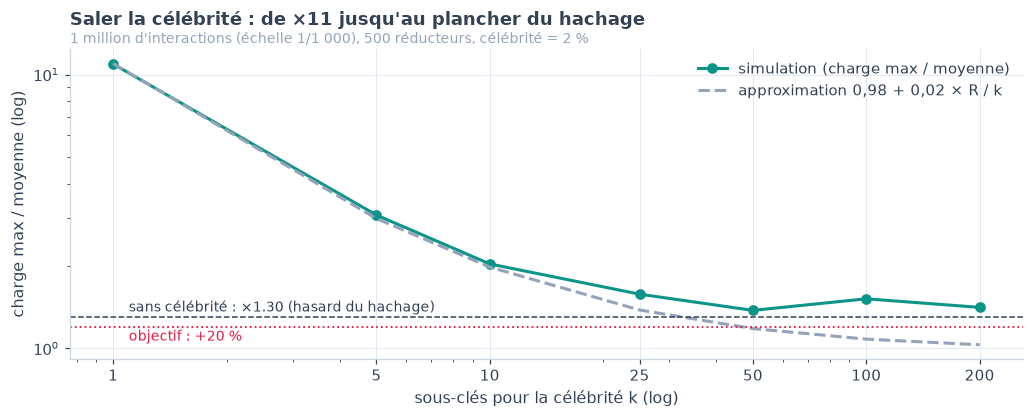

k,1,5,10,25,50,100,200
charge max (simulée),21861.00,6137.00,4067.00,3153.00,2751.00,3033.00,2821.00
rapport à la moyenne,10.93,3.07,2.03,1.58,1.38,1.52,1.41


In [5]:
N, R, part = 1_000_000, 500, 0.02             # échelle 1/1 000
rng = np.random.default_rng(3)
n_cel = int(N * part)
keys = np.concatenate([np.zeros(n_cel, dtype=int), rng.integers(1, 50_000, N - n_cel)])
sans_cel = B.reducer_loads(keys[keys != 0], R)
plancher = sans_cel.max() / (N / R)            # déséquilibre dû au seul hasard du hachage
ks = [1, 5, 10, 25, 50, 100, 200]
mx = [B.reducer_loads(keys, R).max() if k == 1 else B.salted_loads(keys, R, [0], k, seed=k).max() for k in ks]
theo = [N * (1 - part) / R + n_cel / k for k in ks]
fig, ax = plt.subplots(figsize=(9.5, 3.9))
ax.loglog(ks, np.array(mx) / (N / R), "o-", color=TEAL, label="simulation (charge max / moyenne)")
ax.loglog(ks, np.array(theo) / (N / R), "--", color=GRAY, label="approximation 0,98 + 0,02 × R / k")
ax.axhline(1.2, color=ROSE, ls=":", lw=1.2)
ax.text(1.1, 1.17, "objectif : +20 %", color=ROSE, fontsize=9, va="top")
ax.axhline(plancher, color=SLATE, ls="--", lw=1)
ax.text(1.1, plancher * 1.05, f"sans célébrité : ×{plancher:.2f} (hasard du hachage)", color=SLATE, fontsize=9)
ax.set_xlabel("sous-clés pour la célébrité k (log)"); ax.set_ylabel("charge max / moyenne (log)")
ax.set_xticks(ks); ax.set_xticklabels(ks)
ax.set_title("Saler la célébrité : de ×11 jusqu'au plancher du hachage")
subtitle(ax, "1 million d'interactions (échelle 1/1 000), 500 réducteurs, célébrité = 2 %")
ax.legend()
plt.tight_layout(); plt.show()
pd.DataFrame({"k": ks, "charge max (simulée)": mx, "rapport à la moyenne": np.round(np.array(mx) / (N / R), 2)}).set_index("k").T

La simulation confirme le facteur 11 sans salage, et le salage élimine l'excès dû à la
célébrité vers $k = 50$. Mais l'objectif de +20 % n'est pas atteint : même **sans**
célébrité, le réducteur le plus chargé dépasse déjà la moyenne d'environ 30 %. Chaque
réducteur reçoit une centaine de clés d'une vingtaine d'enregistrements chacune ; les
fluctuations du hachage valent environ ±10 % d'un réducteur à l'autre, et le maximum
sur 500 réducteurs se situe vers trois écarts-types. L'approximation $0{,}98 + 0{,}02
R/k$ suppose une répartition parfaite ; en pratique, on vise le plancher du hachage, ou
l'on utilise plus de clés par réducteur (moins de réducteurs, ou un partitionnement par
plages équilibrées).

> **À retenir.** Une clé qui pèse une fraction $f$ des données impose une charge
> d'environ $f \cdot R$ fois la moyenne à son réducteur. La saler en $k \approx f R / \epsilon$
> sous-clés ramène son excès à $\epsilon$, au prix de $k$ copies de l'enregistrement de
> dimension ; il reste le déséquilibre propre au hachage, d'autant plus fort que chaque
> réducteur reçoit peu de clés.

## Exercice 10.9 : plus courts chemins en Pregel

**Énoncé.** On veut la distance (en kilomètres) de chaque ville d'un réseau routier
synthétique à la ville 0.

1. Écrire la fonction `compute` d'un calcul Pregel de plus courts chemins depuis une
   source : chaque sommet garde la meilleure distance connue ; à réception de messages,
   s'il trouve mieux, il met à jour et propose à chaque voisin sa distance plus la
   longueur de l'arc.
2. L'exécuter avec `B.pregel`, vérifier le résultat avec l'algorithme de Dijkstra.
3. Combien de super-étapes faut-il ? Relier ce nombre à la structure du graphe (nombre
   d'arcs des plus courts chemins). Combien de messages au total, et comment évoluent-ils ?

**Rappels.** Modèle Pregel : super-étapes, messages livrés à l'étape suivante, vote
d'arrêt (cours 4, section 4, section *The Pregel processing model*).

In [6]:
rng = np.random.default_rng(5)
n = 1500
pos = rng.random((n, 2)) * 500                                  # villes dans un carré de 500 km
arcs = {v: [] for v in range(n)}
for v in range(n):
    d2 = ((pos - pos[v]) ** 2).sum(axis=1)
    for u in np.argsort(d2)[1:5]:                              # routes vers les 4 voisines les plus proches
        w = float(np.sqrt(d2[u])) * rng.uniform(1.0, 1.3)
        arcs[v].append((int(u), w))
        arcs[int(u)].append((v, w))


def compute(v, dist, msgs, step, voisins):
    meilleure = min([dist] + msgs)
    if (step == 0 and v == 0) or meilleure < dist:
        return meilleure, [(u, meilleure + w) for u, w in voisins], True
    return dist, [], True


init = {v: (0.0 if v == 0 else math.inf) for v in range(n)}
dist, hist = B.pregel(init, arcs, compute, max_supersteps=500)

# vérification : Dijkstra
ref = {v: math.inf for v in range(n)}
ref[0] = 0.0
tas = [(0.0, 0)]
nb_arcs = {0: 0}
while tas:
    d_, v = heapq.heappop(tas)
    if d_ > ref[v]:
        continue
    for u, w in arcs[v]:
        if d_ + w < ref[u]:
            ref[u] = d_ + w
            nb_arcs[u] = nb_arcs[v] + 1
            heapq.heappush(tas, (ref[u], u))
atteints = [v for v in range(n) if ref[v] < math.inf]
assert all(abs(dist[v] - ref[v]) < 1e-6 for v in atteints)
H = pd.DataFrame(hist)
print(f"{len(atteints)} villes atteintes, distances identiques à Dijkstra ; {len(H)} super-étapes, "
      f"{H.messages.sum():,} messages ; plus long chemin optimal : {max(nb_arcs.values())} arcs".replace(",", " "))

1500 villes atteintes  distances identiques à Dijkstra ; 61 super-étapes  46 440 messages ; plus long chemin optimal : 59 arcs


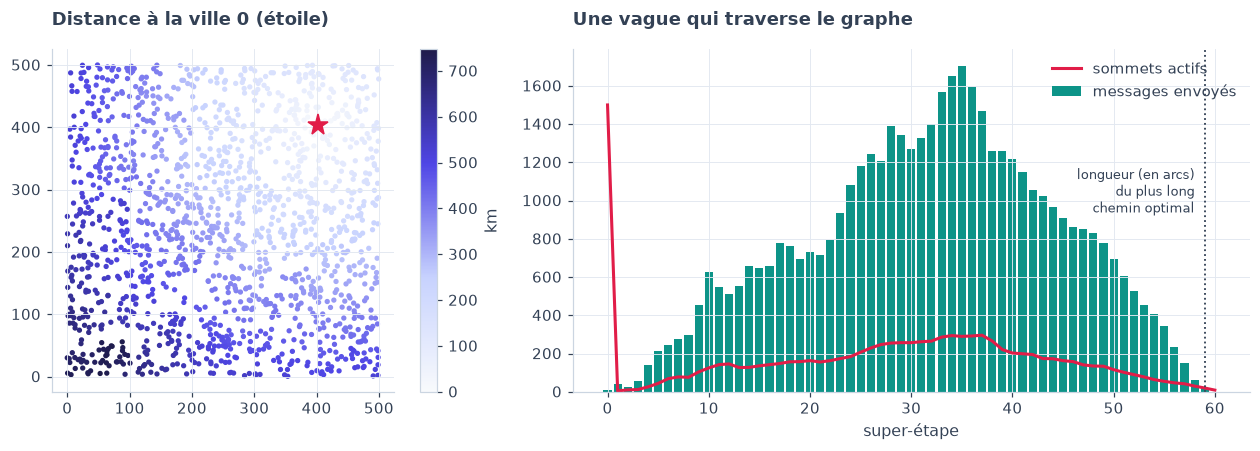

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2), gridspec_kw={"width_ratios": [1, 1.3]})
sc = axes[0].scatter(pos[atteints, 0], pos[atteints, 1], c=[ref[v] for v in atteints], s=6, cmap="ddia_seq")
axes[0].plot(*pos[0], "*", color=ROSE, ms=14)
axes[0].set_aspect("equal"); axes[0].set_title("Distance à la ville 0 (étoile)")
plt.colorbar(sc, ax=axes[0], label="km", fraction=0.046)
axes[1].bar(H.super_etape, H.messages, color=TEAL, label="messages envoyés")
axes[1].plot(H.super_etape, H.sommets_actifs, color=ROSE, label="sommets actifs")
axes[1].axvline(max(nb_arcs.values()), color=SLATE, ls=":", lw=1.2)
axes[1].text(max(nb_arcs.values()) - 1, H.messages.max() * 0.55, "longueur (en arcs)\ndu plus long\nchemin optimal", fontsize=8.5, ha="right")
axes[1].set_xlabel("super-étape"); axes[1].set_title("Une vague qui traverse le graphe")
axes[1].legend()
plt.tight_layout(); plt.show()

**Solution.** La fonction `compute` ci-dessus prend le minimum entre la distance connue
et les propositions reçues ; elle ne parle que si sa distance s'améliore (ou à
l'étape 0 pour la source), puis vote l'arrêt. Le résultat coïncide avec Dijkstra.

Le nombre de super-étapes est au moins le nombre d'arcs du plus long des plus courts
chemins (l'information avance d'un arc par étape) ; il peut le dépasser un peu, car un
chemin à **moins** d'arcs mais plus long en kilomètres arrive parfois d'abord, puis est
corrigé par un chemin à plus d'arcs. Les messages forment une vague : peu au départ,
un pic quand le front traverse le cœur du graphe, puis quelques corrections. Au total,
on envoie plus de messages que Dijkstra n'examine d'arcs (les distances provisoires
sont souvent améliorées plusieurs fois), mais chaque super-étape est massivement
parallèle.

> **À retenir.** En Pregel, un algorithme de graphe s'écrit « du point de vue d'un
> sommet » ; le nombre de super-étapes suit la profondeur (en arcs) du calcul, et le
> trafic suit le front de l'information. Les sommets inactifs ne coûtent rien.

## Exercice 10.10 : écrire dans la base de production, ou construire et basculer ?

**Énoncé.** Un job nocturne calcule 10 recommandations pour chacun de 50 millions
d'utilisateurs (un enregistrement de 400 octets par utilisateur). Deux options :

- (A) 200 tâches écrivent directement dans la base de production, une écriture par
  utilisateur, chacune avec un temps de réponse de 2 ms (une connexion par tâche) ;
- (B) le job écrit des fichiers triés (format de la base), copiés ensuite sur les
  20 serveurs de la base à 200 Mo/s chacun, puis basculés atomiquement.

1. Durée de l'écriture en (A) et en (B) ?
2. En (A), le job échoue à 60 % et est relancé depuis le début le lendemain matin.
   Quelle part des utilisateurs voit des recommandations neuves, et quelle part des
   anciennes, pendant ce temps ? Un utilisateur peut-il voir un mélange ?
3. En (A), une tâche est préemptée et relancée. Que se passe-t-il si la base stocke les
   recommandations comme des lignes ajoutées (et non remplacées) ? Comment rendre
   l'écriture idempotente ?
4. Quels avantages opérationnels apporte (B) en cas de bogue découvert après coup ?

**Rappels.** Pourquoi ne pas écrire depuis un job dans la base ; construction d'une
base clé-valeur par lots et publication atomique : cours 5, sections 1 et 3 (section
*Key-value stores as batch process output*).

**Solution.**

*1.* (A) : $5 \cdot 10^7$ écritures de 2 ms réparties sur 200 connexions :
$5 \cdot 10^7 \times 0{,}002 / 200 = 500$ s, si la base tient 100 000 écritures par
seconde en plus de son trafic, ce qui est loin d'être acquis (sinon, ses temps de
réponse s'envolent, voir le cours 5). (B) : 20 Go au total, 1 Go par serveur, copié en
5 s ; la construction des fichiers est un simple parcours séquentiel, fait hors
production.

*2.* 60 % des utilisateurs ont des recommandations neuves, 40 % des anciennes, jusqu'à la
relance ; la base n'est cohérente avec aucune exécution du job. Si les 10
recommandations d'un utilisateur sont écrites en plusieurs fois, un utilisateur peut même
voir un mélange des deux versions.

*3.* La tâche relancée réécrit les utilisateurs qu'elle avait déjà traités : avec des
lignes ajoutées, ils ont 20 recommandations, dont 10 en double. Pour être idempotent, on
écrit par **remplacement** sur une clé (identifiant d'utilisateur), si possible avec un
numéro de version de l'exécution, pour qu'une écriture plus ancienne ne puisse pas
écraser une plus récente.

*4.* Avec (B), l'ancienne version reste disponible : on rebascule en une opération si les
recommandations sont mauvaises, et l'on peut comparer automatiquement la nouvelle sortie
à l'ancienne **avant** de la publier. Le job n'a pas besoin d'accès réseau à la
production.

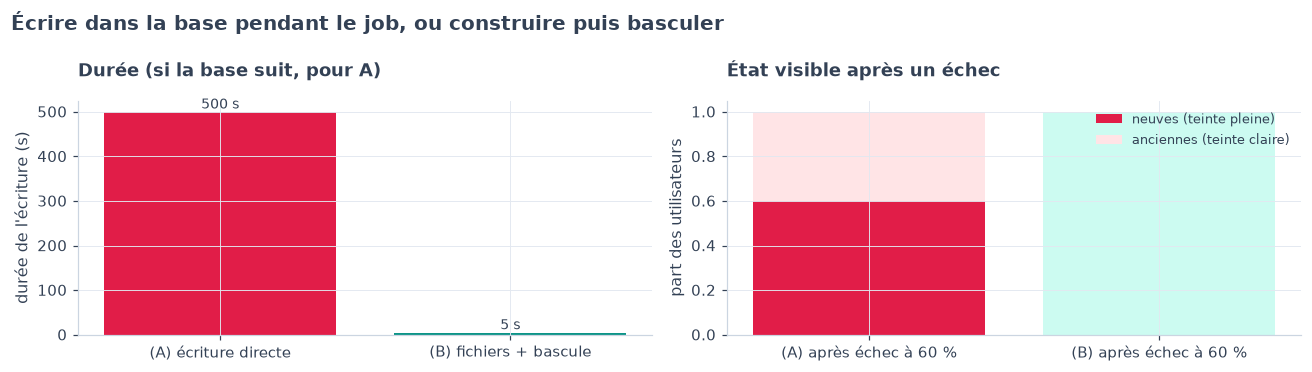

In [8]:
rng = np.random.default_rng(6)
n_users = 50_000
ancien = {u: ("v1", u % 97) for u in range(n_users)}
base_a = dict(ancien)
for u in range(int(n_users * 0.6)):                               # (A) : le job meurt à 60 %
    base_a[u] = ("v2", (u * 7) % 97)
neuf_a = sum(v[0] == "v2" for v in base_a.values()) / n_users
base_b = dict(ancien)                                             # (B) : rien n'est publié avant la fin
neuf_b = sum(v[0] == "v2" for v in base_b.values()) / n_users
t_a = 50e6 * 0.002 / 200
t_b = 50e6 * 400 / 20 / 200e6
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].bar(["(A) écriture directe", "(B) fichiers + bascule"], [t_a, t_b], color=[ROSE, TEAL])
for i, v in enumerate([t_a, t_b]):
    axes[0].text(i, v, f"{v:.0f} s", ha="center", va="bottom", fontsize=9)
axes[0].set_ylabel("durée de l'écriture (s)"); axes[0].set_title("Durée (si la base suit, pour A)")
axes[1].bar(["(A) après échec à 60 %", "(B) après échec à 60 %"], [neuf_a, neuf_b], color=[ROSE, TEAL], label="neuves (teinte pleine)")
axes[1].bar(["(A) après échec à 60 %", "(B) après échec à 60 %"], [1 - neuf_a, 1 - neuf_b], bottom=[neuf_a, neuf_b],
            color=[LIGHT[ROSE], LIGHT[TEAL]], label="anciennes (teinte claire)")
axes[1].set_ylabel("part des utilisateurs"); axes[1].set_title("État visible après un échec")
axes[1].legend(loc="upper right", fontsize=8.5)
finish(fig, "Écrire dans la base pendant le job, ou construire puis basculer")
plt.show()

> **À retenir.** Écrire depuis un job dans la base de production expose des états
> intermédiaires (mélange de versions, doublons après relance) et met la base en danger.
> Construire les fichiers de la base puis basculer atomiquement garde la garantie
> « tout ou rien » et un retour arrière immédiat.